In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the existing SQLite database
conn = sqlite3.connect("reel_insights.db")

# Load datasets
movies = pd.read_sql_query("SELECT * FROM movies", conn)
genres = pd.read_sql_query("SELECT * FROM genres", conn)
movie_genres = pd.read_sql_query("SELECT * FROM movie_genres", conn)
cast = pd.read_sql_query('SELECT * FROM "cast"', conn)
crew = pd.read_sql_query("SELECT * FROM crew", conn)
movie_keywords = pd.read_sql_query("SELECT * FROM movie_keywords", conn)

print("All datasets loaded successfully!")
print("Movies:", movies.shape)
print("Genres:", genres.shape)
print("Movie Genres:", movie_genres.shape)
print("Cast:", cast.shape)
print("Crew:", crew.shape)
print("Movie Keywords:", movie_keywords.shape)

All datasets loaded successfully!
Movies: (2503, 18)
Genres: (19, 2)
Movie Genres: (6878, 2)
Cast: (24902, 6)
Crew: (7289, 6)
Movie Keywords: (41681, 3)


In [2]:
# Convert release_date into datetime format
movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

# Extract release year
movies["release_year"] = movies["release_date"].dt.year

# Count movies released each year
movies_per_year = (
    movies.groupby("release_year")["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
    .dropna(subset=["release_year"])
    .sort_values("release_year")
)

display(movies_per_year)

,release_year,total_movies
0,1921,1
1,1922,1
2,1927,1
3,1931,2
4,1936,1
...,...,...
84,2022,65
85,2023,62
86,2024,43
87,2025,26


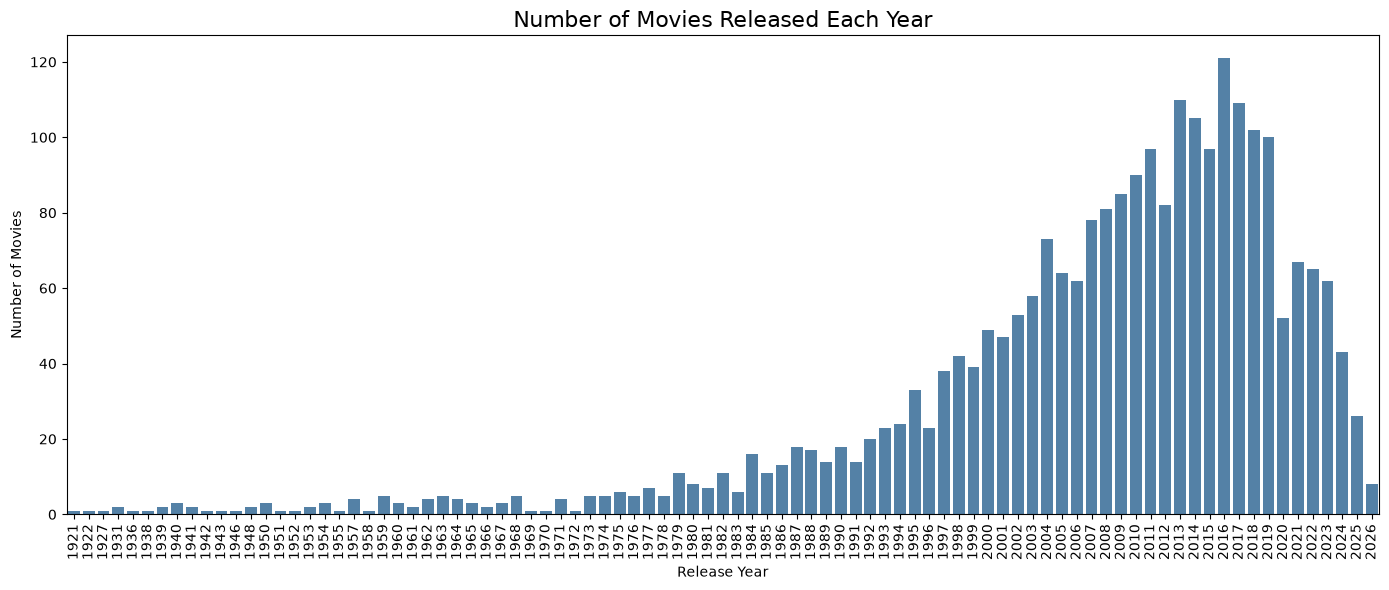

In [3]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=movies_per_year,
    x="release_year",
    y="total_movies",
    color="steelblue"
)

plt.title("Number of Movies Released Each Year", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [4]:
peak_year = movies_per_year.loc[
    movies_per_year["total_movies"].idxmax()
]

print("Peak Release Year:", int(peak_year["release_year"]))
print("Number of Movies:", int(peak_year["total_movies"]))

Peak Release Year: 2016
Number of Movies: 121


In [5]:
# Join movies with movie genres
genre_ratings = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_ratings = genre_ratings.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="left"
)

# Calculate average rating for each genre
genre_rating_summary = (
    genre_ratings.groupby("genre_name")
    .agg(
        total_movies=("movie_id", "nunique"),
        average_rating=("vote_average", "mean")
    )
    .reset_index()
    .sort_values("average_rating", ascending=False)
)

genre_rating_summary["average_rating"] = (
    genre_rating_summary["average_rating"].round(2)
)

display(genre_rating_summary)

,genre_name,total_movies,average_rating
17,War,85,7.36
9,History,112,7.34
11,Music,49,7.32
5,Documentary,1,7.31
6,Drama,937,7.25
2,Animation,246,7.20
18,Western,33,7.13
13,Romance,349,7.03
15,TV Movie,4,7.01
4,Crime,387,7.01


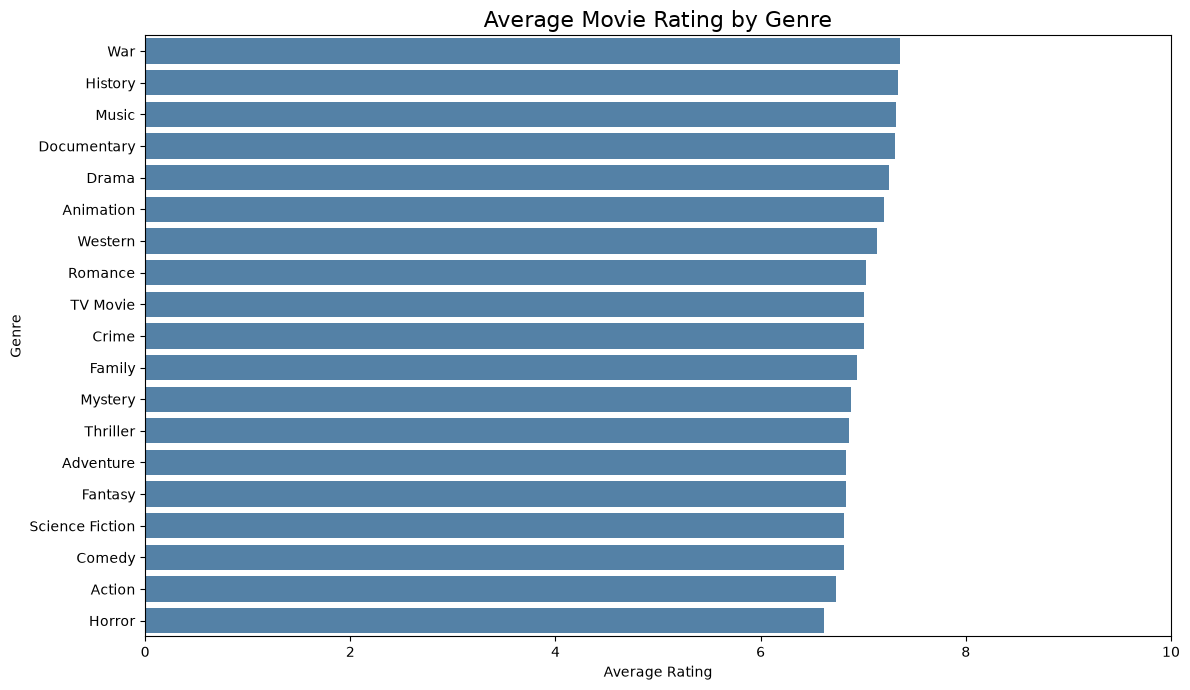

In [6]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_rating_summary,
    x="average_rating",
    y="genre_name",
    color="steelblue"
)

plt.title("Average Movie Rating by Genre", fontsize=16)
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.xlim(0, 10)
plt.tight_layout()

plt.show()

In [7]:
top_revenue_movies = (
    movies.dropna(subset=["revenue_clean"])
    .sort_values("revenue_clean", ascending=False)
    .head(10)
)

display(
    top_revenue_movies[
        ["title", "revenue_clean", "budget_clean"]
    ]
)

,title,revenue_clean,budget_clean
1136,Avatar,2.923706e+09,237000000.0
1811,Avengers: Endgame,2.799439e+09,356000000.0
1436,Avatar: The Way of Water,2.334485e+09,460000000.0
217,Titanic,2.264162e+09,200000000.0
1575,Star Wars: The Force Awakens,2.068224e+09,245000000.0
1812,Avengers: Infinity War,2.052415e+09,300000000.0
2345,Spider-Man: No Way Home,1.921207e+09,200000000.0
2481,Zootopia 2,1.868209e+09,150000000.0
2471,Inside Out 2,1.698864e+09,200000000.0
1561,Jurassic World,1.671537e+09,150000000.0


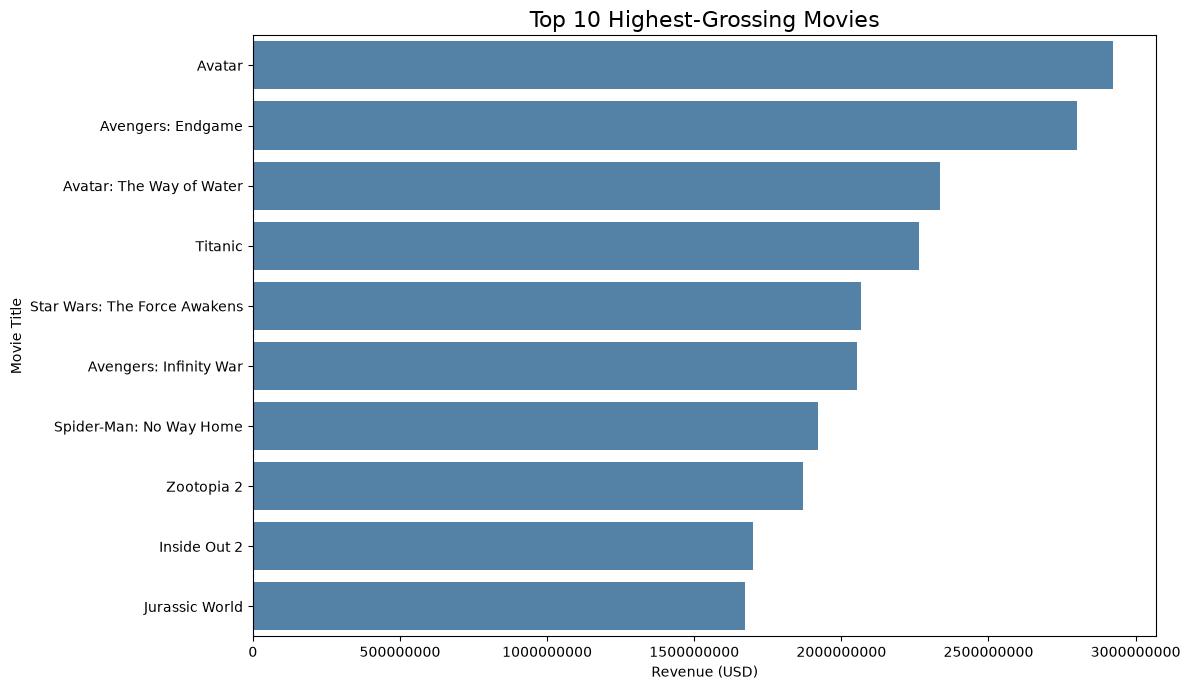

In [8]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_revenue_movies,
    x="revenue_clean",
    y="title",
    color="steelblue"
)

plt.title("Top 10 Highest-Grossing Movies", fontsize=16)
plt.xlabel("Revenue (USD)")
plt.ylabel("Movie Title")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()

plt.show()

In [9]:
# Join movie genres with genre names
genre_movie_counts = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

# Count movies in each genre
genre_counts = (
    genre_movie_counts.groupby("genre_name")["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
    .sort_values("total_movies", ascending=False)
    .head(10)
)

display(genre_counts)

,genre_name,total_movies
6,Drama,937
0,Action,808
3,Comedy,762
1,Adventure,674
16,Thriller,673
14,Science Fiction,463
8,Fantasy,396
4,Crime,387
13,Romance,349
7,Family,344


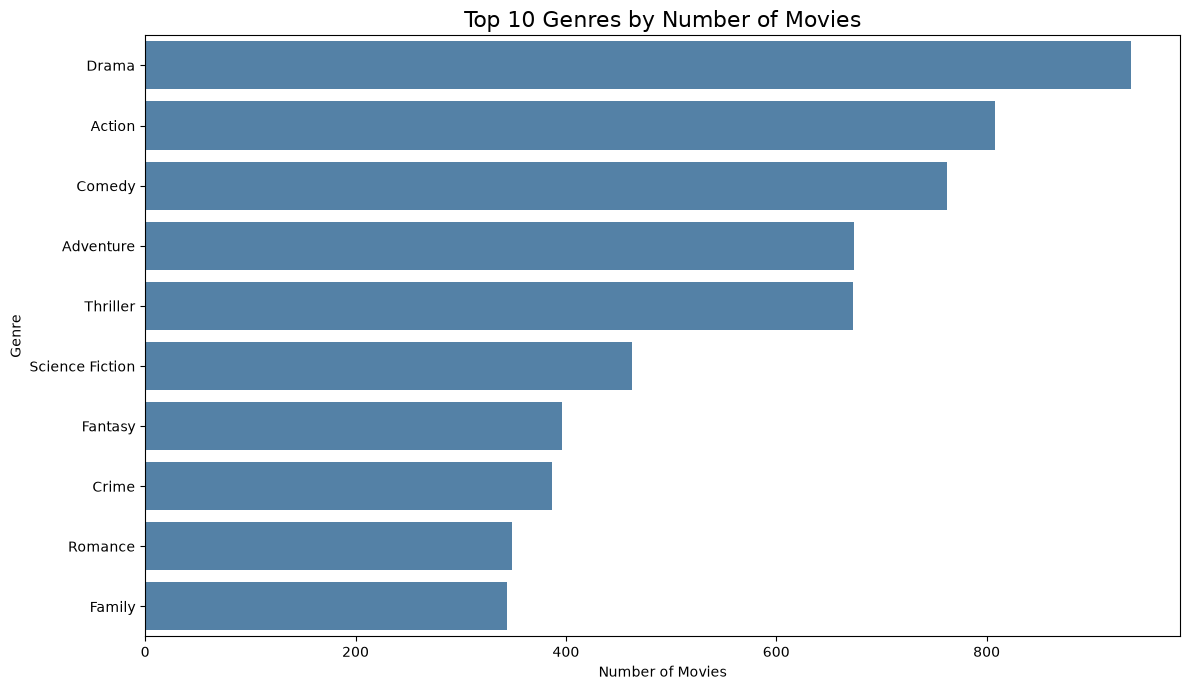

In [10]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_counts,
    x="total_movies",
    y="genre_name",
    color="steelblue"
)

plt.title("Top 10 Genres by Number of Movies", fontsize=16)
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()

plt.show()

In [11]:
financial_movies = movies.dropna(
    subset=["budget_clean", "revenue_clean"]
).copy()

# Exclude zero or negative values for a meaningful financial comparison
financial_movies = financial_movies[
    (financial_movies["budget_clean"] > 0) &
    (financial_movies["revenue_clean"] > 0)
]

display(
    financial_movies[
        ["title", "budget_clean", "revenue_clean"]
    ].head(10)
)

print("Movies included:", len(financial_movies))


,title,budget_clean,revenue_clean
0,Four Rooms,4000000.0,4257354.0
1,Star Wars,11000000.0,775398007.0
2,Finding Nemo,94000000.0,940335536.0
3,Forrest Gump,55000000.0,677387716.0
4,American Beauty,15000000.0,356296601.0
5,Citizen Kane,839727.0,23218000.0
6,The Fifth Element,90000000.0,263920180.0
7,Metropolis,5300000.0,1350322.0
8,Pirates of the Caribbean: The Curse of the Bla...,140000000.0,655011224.0
9,Kill Bill: Vol. 1,30000000.0,180906076.0


Movies included: 2370


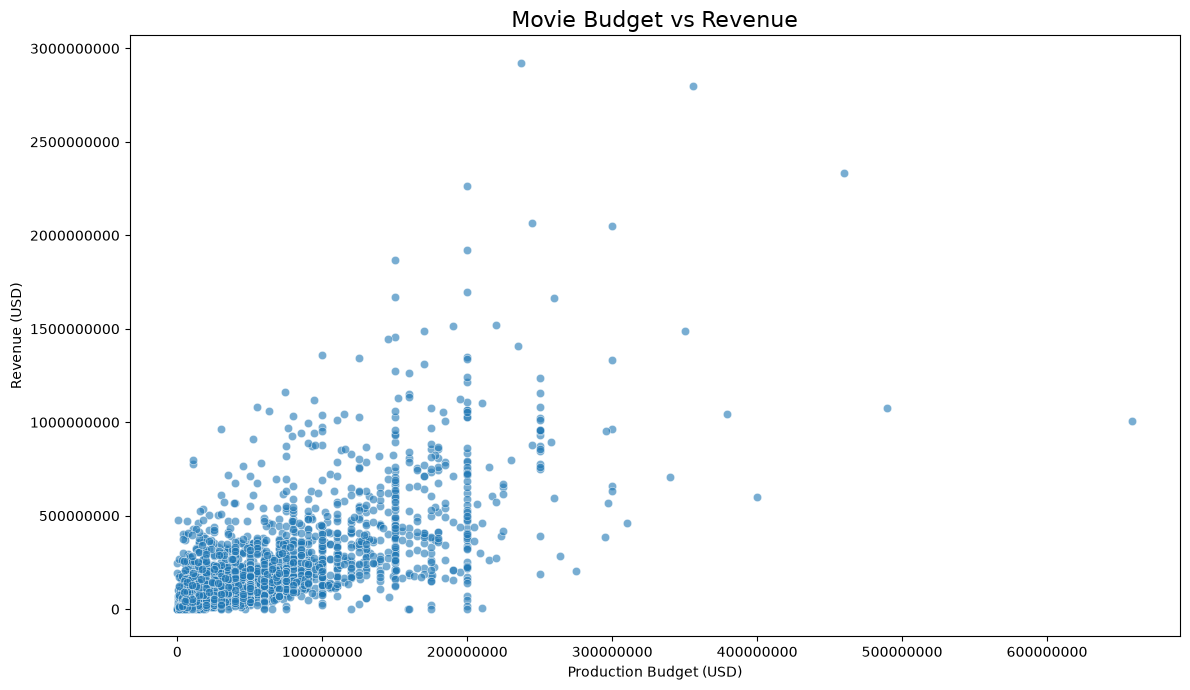

In [12]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=financial_movies,
    x="budget_clean",
    y="revenue_clean",
    alpha=0.6
)

plt.title("Movie Budget vs Revenue", fontsize=16)
plt.xlabel("Production Budget (USD)")
plt.ylabel("Revenue (USD)")

plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()

plt.show()

In [13]:
# Extract release month
movies["release_month"] = movies["release_date"].dt.month

# Count movies released in each month
monthly_releases = (
    movies.dropna(subset=["release_month"])
    .groupby("release_month")["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
)

# Convert month numbers into month names
monthly_releases["month_name"] = (
    pd.to_datetime(
        monthly_releases["release_month"],
        format="%m"
    ).dt.month_name()
)

display(monthly_releases)

C:\Users\priya\AppData\Local\Temp\ipykernel_36568\2281309440.py:14: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  pd.to_datetime(


,release_month,total_movies,month_name
0,1,108,January
1,2,169,February
2,3,191,March
3,4,145,April
4,5,209,May
5,6,279,June
6,7,236,July
7,8,174,August
8,9,208,September
9,10,246,October


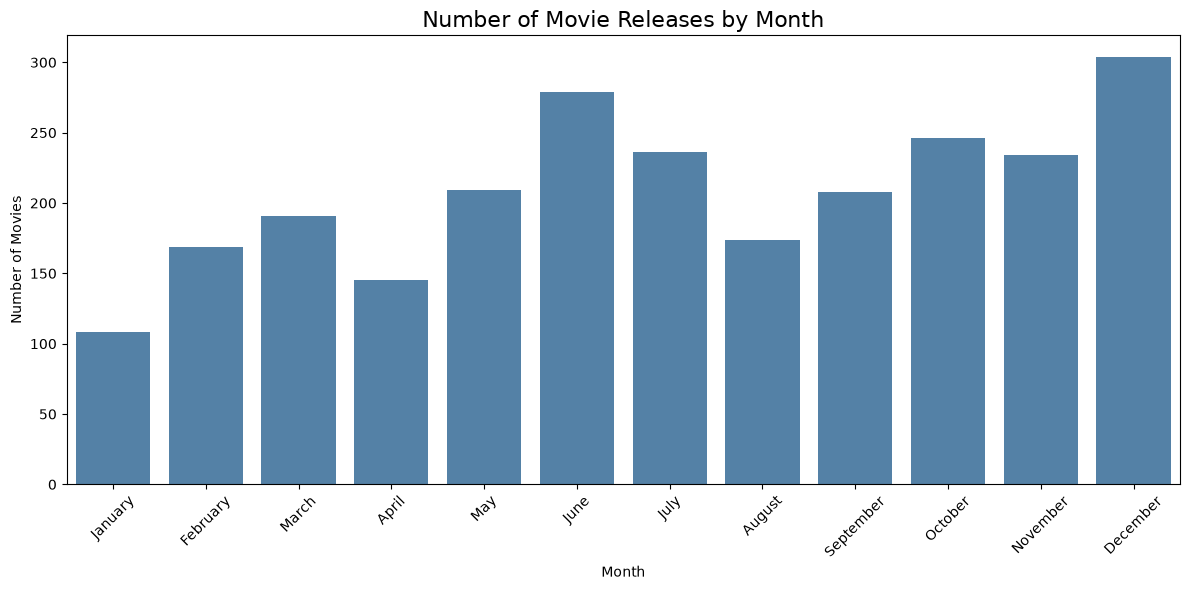

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_releases,
    x="month_name",
    y="total_movies",
    color="steelblue",
    order=[
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ]
)

plt.title("Number of Movie Releases by Month", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [15]:
# Remove duplicate actor-movie combinations
actor_movie_data = cast[
    ["person_id", "actor_name", "movie_id"]
].drop_duplicates(
    subset=["person_id", "movie_id"]
)

# Count movies for each actor
actor_movie_counts = (
    actor_movie_data.groupby("actor_name")["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
    .sort_values("total_movies", ascending=False)
    .head(10)
)

display(actor_movie_counts)

,actor_name,total_movies
9526,Samuel L. Jackson,39
9102,Robert De Niro,38
1255,Brad Pitt,38
5317,Johnny Depp,37
10599,Tom Hanks,33
11031,Willem Dafoe,32
7090,Mark Wahlberg,32
9630,Scarlett Johansson,32
10586,Tom Cruise,31
7814,Morgan Freeman,31


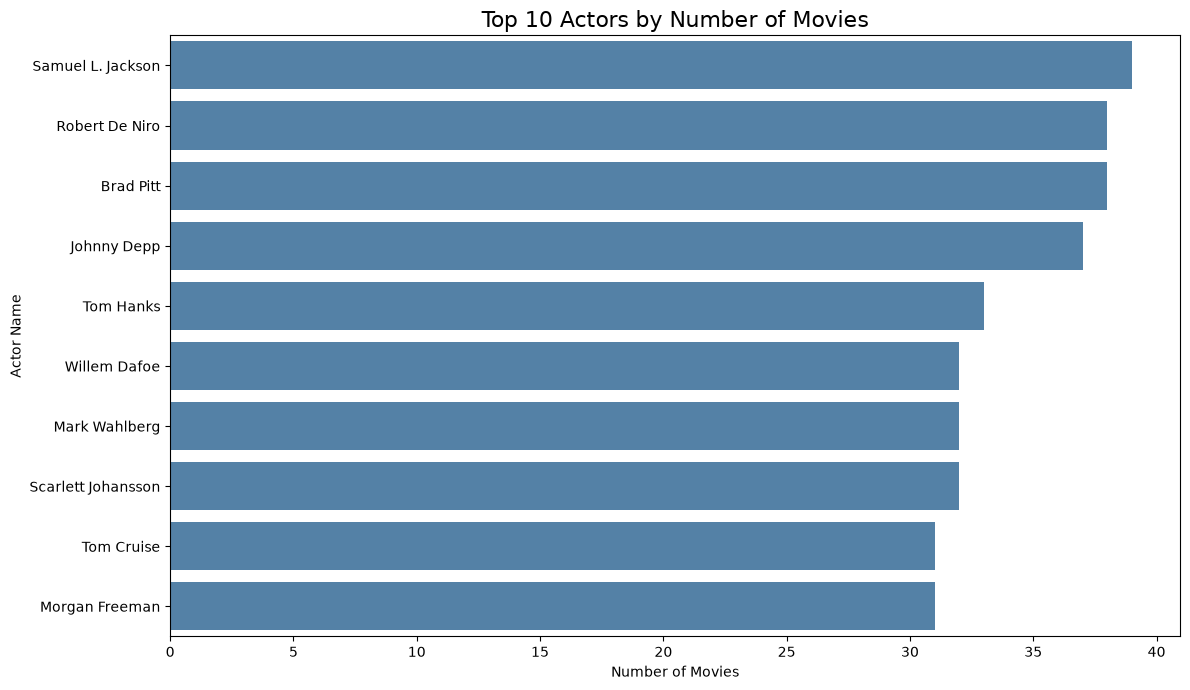

In [16]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=actor_movie_counts,
    x="total_movies",
    y="actor_name",
    color="steelblue"
)

plt.title("Top 10 Actors by Number of Movies", fontsize=16)
plt.xlabel("Number of Movies")
plt.ylabel("Actor Name")
plt.tight_layout()

plt.show()

In [17]:
rating_data = movies[
    movies["vote_average"].notna()
].copy()

print("Total movies with ratings:", len(rating_data))

print("Average movie rating:", round(
    rating_data["vote_average"].mean(), 2
))

Total movies with ratings: 2503
Average movie rating: 6.94


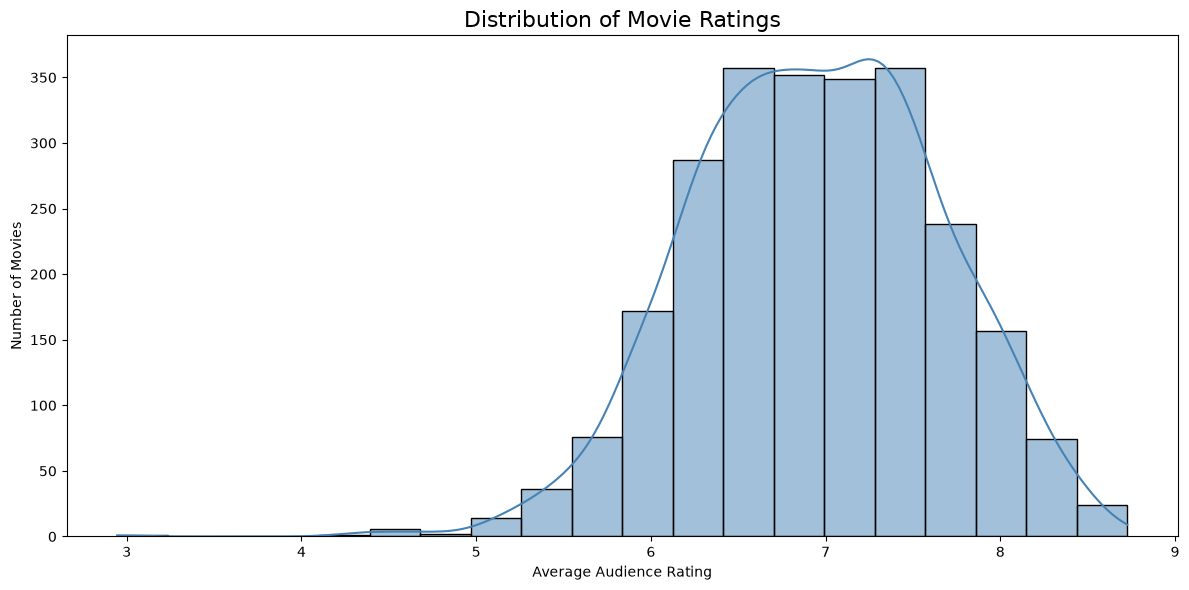

In [18]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=rating_data,
    x="vote_average",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Movie Ratings", fontsize=16)
plt.xlabel("Average Audience Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.show()

In [19]:
# Select movies with valid financial data
roi_movies = movies.dropna(
    subset=["budget_clean", "revenue_clean"]
).copy()

# Exclude movies with budget below $1 million
roi_movies = roi_movies[
    (roi_movies["budget_clean"] >= 1000000) &
    (roi_movies["revenue_clean"] > 0)
]

# Calculate ROI
roi_movies["roi"] = (
    (roi_movies["revenue_clean"] - roi_movies["budget_clean"])
    / roi_movies["budget_clean"]
) * 100

# Select top 10 movies
top_roi_movies = roi_movies.sort_values(
    "roi",
    ascending=False
).head(10)

display(
    top_roi_movies[
        ["title", "budget_clean", "revenue_clean", "roi"]
    ]
)

,title,budget_clean,revenue_clean,roi
2191,Dragon Ball Super: Broly,1000000.0,125002821.0,12400.282100
152,Snow White and the Seven Dwarfs,1488423.0,184925486.0,12324.256142
1211,The Rocky Horror Picture Show,1400000.0,171181400.0,12127.242857
412,Rocky,1000000.0,117253345.0,11625.334500
300,Gone with the Wind,4000000.0,402352579.0,9958.814475
794,The Jungle Book,4000000.0,378000000.0,9350.000000
1001,Cinderella,2900000.0,263600000.0,8989.655172
78,Saw,1200000.0,104045735.0,8570.477917
1055,One Hundred and One Dalmatians,3600000.0,303000000.0,8316.666667
221,E.T. the Extra-Terrestrial,10500000.0,797307407.0,7493.403876


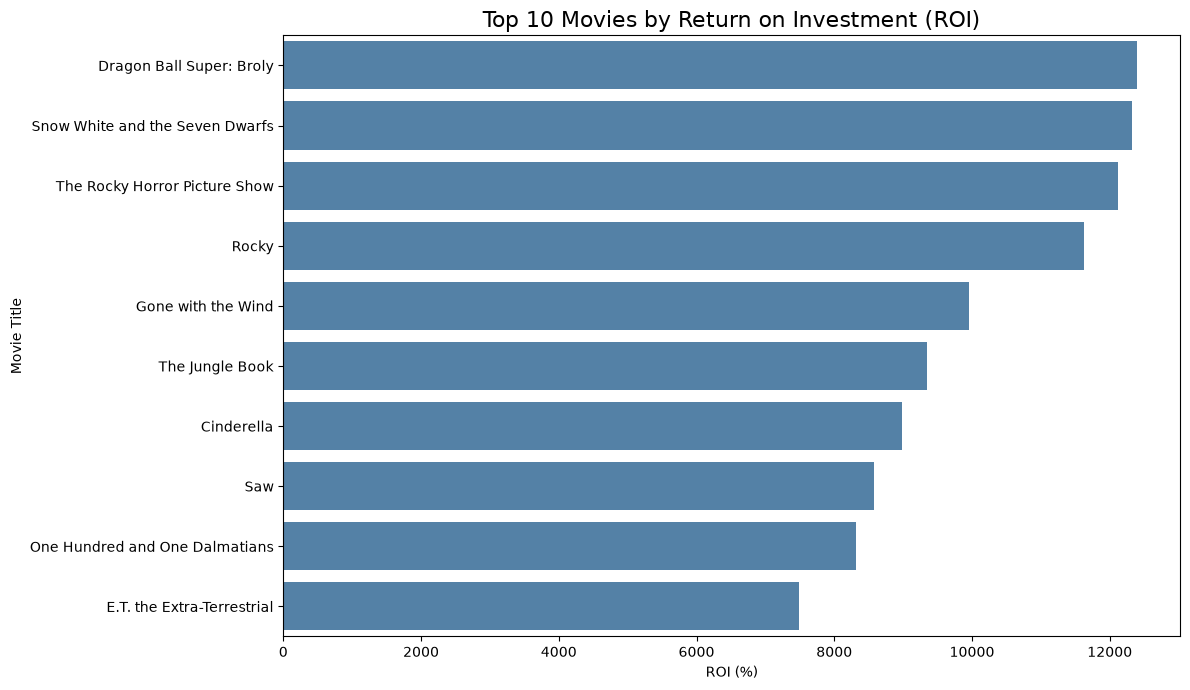

In [20]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_roi_movies,
    x="roi",
    y="title",
    color="steelblue"
)

plt.title("Top 10 Movies by Return on Investment (ROI)", fontsize=16)
plt.xlabel("ROI (%)")
plt.ylabel("Movie Title")
plt.tight_layout()

plt.show()

In [21]:
runtime_data = movies[
    movies["runtime"].notna() &
    (movies["runtime"] > 0)
].copy()

print("Total movies with valid runtime:", len(runtime_data))

print("Average Runtime:", round(
    runtime_data["runtime"].mean(), 2
), "minutes")

print("Median Runtime:", round(
    runtime_data["runtime"].median(), 2
), "minutes")

Total movies with valid runtime: 2503
Average Runtime: 114.41 minutes
Median Runtime: 111.0 minutes


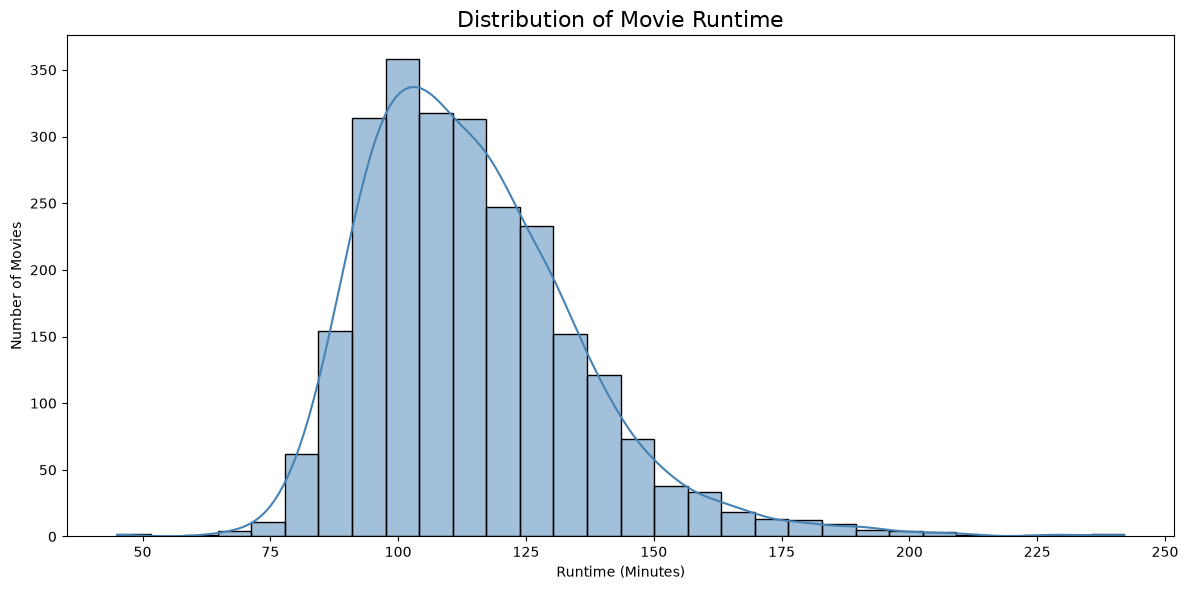

In [22]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=runtime_data,
    x="runtime",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Movie Runtime", fontsize=16)
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.show()